# v2 checks (2026-11-16)

Checks on the first v2 trained models (`_p5_n10000` × `_biasnoisenestv2_p9_n320000` × `_noisefly`, pk+pgm, kp0.35/kpgm0.25, v1 best hyperparameters `best-rand30v1_nbest{0,1,2}`).

## 1. Noise in θ vs not: SHAMe OOD posteriors

A/B test of whether the noise amplitudes $A_n$ are included as NPE parameters (`exclude_noise: false`, 11 params) or left out (`exclude_noise: true`, 6 params). The training data are identical in both cases. Only the θ the flow is conditioned on differs.

Tested on the SHAMe OOD mocks at three $\bar n$, with truths from `utils_model.bias_dict_shame` (÷2 convention on b2/bs2). nbest0 is still training and appears here once its samples exist.

In [1]:
import os
import sys
from pathlib import Path

os.environ["MUCHISIMOCKS_DATA"] = "/scratch/kstoreyf/muchisimocks/data_v2"
os.environ["MUCHISIMOCKS_RESULTS"] = "/scratch/kstoreyf/muchisimocks/results_v2"

REPO_ROOT = Path.cwd()
if REPO_ROOT.name == "notebooks":
    REPO_ROOT = REPO_ROOT.parent
sys.path.insert(0, str(REPO_ROOT / "code"))

import numpy as np
import matplotlib.pyplot as plt

import data_loader
import plotter
import paths

%load_ext autoreload
%autoreload 2

FIG_DIR = REPO_ROOT / "figures" / "2026-11-16_v2_checks"
FIG_DIR.mkdir(parents=True, exist_ok=True)
print("results:", paths.DIR_RESULTS)

results: /scratch/kstoreyf/muchisimocks/results_v2


In [2]:
DIR_SBI = Path(paths.DIR_RESULTS) / "results_sbi"
TAG_MODEL = "sbi_muchisimocks_pk_pgm_kp0.35_kpgm0.25_p5_n10000_biasnoisenestv2_p9_n320000_noisefly_rp_bx32_ntrain10000_best-rand30v1_nbest"
NBAR_TAGS = ["_nbar0.00011", "_nbar0.00022", "_nbar0.00054"]
NBAR_LABELS = {
    "_nbar0.00011": r"$\bar{n}=1.1\times10^{-4}$",
    "_nbar0.00022": r"$\bar{n}=2.2\times10^{-4}$",
    "_nbar0.00054": r"$\bar{n}=5.4\times10^{-4}$",
}
COLOR_NOISE, COLOR_NONOISE = "#B32168", "#79D0EC"
LINESTYLE_NBEST = {0: "-", 1: "--", 2: ":"}

# (label, model dir suffix, color, linestyle, shade)
MODELS = []
for nb in (0, 1, 2):
    MODELS.append((f"noise in θ, nbest{nb}", f"{nb}", COLOR_NOISE, LINESTYLE_NBEST[nb], nb == 1))
    MODELS.append((f"no noise in θ, nbest{nb}", f"{nb}_nonoise", COLOR_NONOISE, LINESTYLE_NBEST[nb], nb == 1))


def load_shame_samples(suffix, tag_mock):
    d = DIR_SBI / f"{TAG_MODEL}{suffix}"
    fn = d / f"samples_test_shame_pk_pgm_kp0.35_kpgm0.25{tag_mock}_pred.npy"
    if not fn.exists():
        return None
    names = list(np.loadtxt(d / "param_names.txt", dtype=str))
    s = np.load(fn)
    return (s[:, 0, :] if s.ndim == 3 else s), names


def shame_truth(tag_mock, param_names):
    p = data_loader.load_params_ood("shame", tag_mock)
    return {pn: float(p[pn]) for pn in param_names}

### Contours, one figure per $\bar n$

Cosmology plus the four bias parameters, unreparameterized from the NPE's σ8×bias coordinates. Pink is noise in θ and blue is no noise in θ. Line style marks the hyperparameter set: nbest0 solid, nbest1 dashed (shaded), nbest2 dotted. Black marks the SHAMe truth.

_nbar0.00011: missing noise in θ, nbest0
_nbar0.00011: missing no noise in θ, nbest0


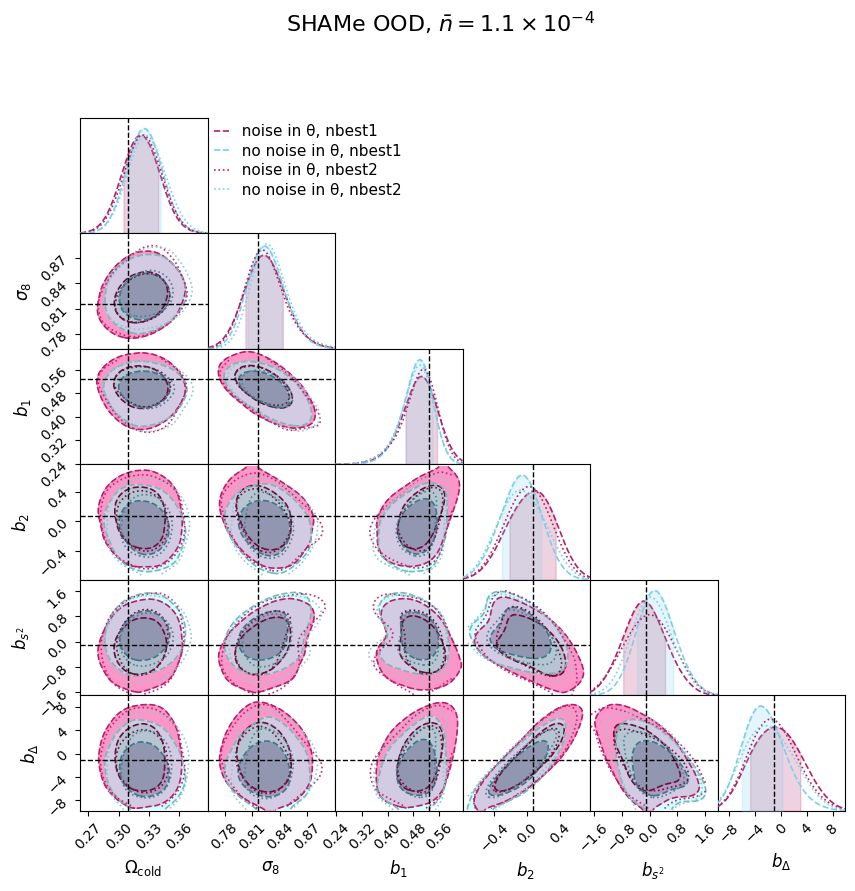

_nbar0.00022: missing noise in θ, nbest0
_nbar0.00022: missing no noise in θ, nbest0


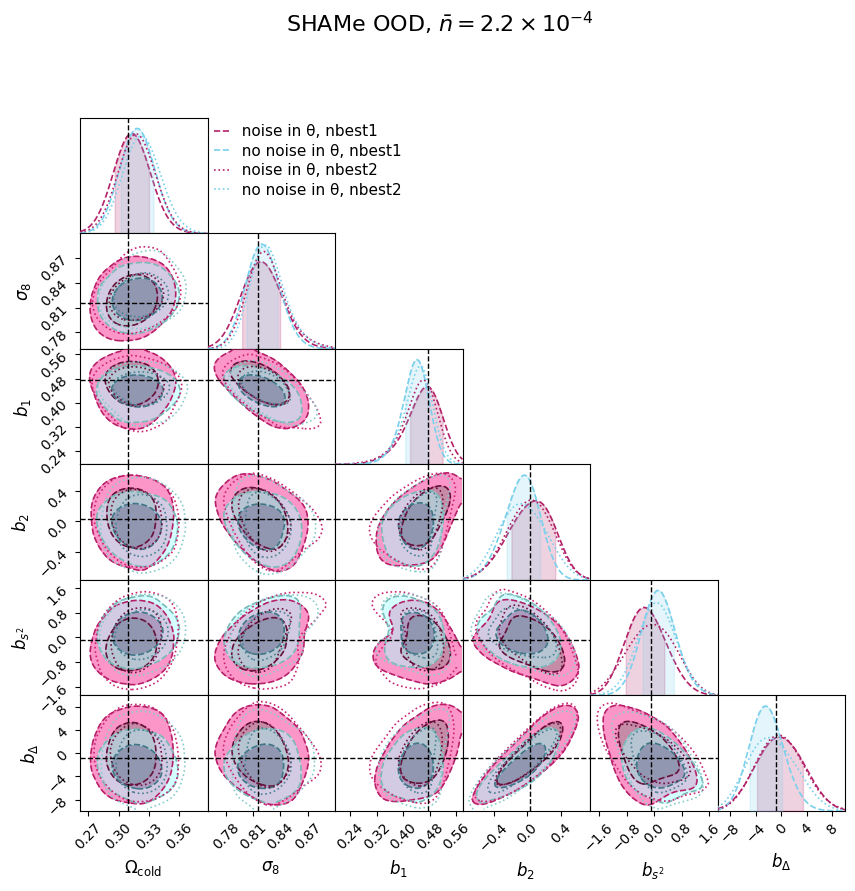

_nbar0.00054: missing noise in θ, nbest0
_nbar0.00054: missing no noise in θ, nbest0


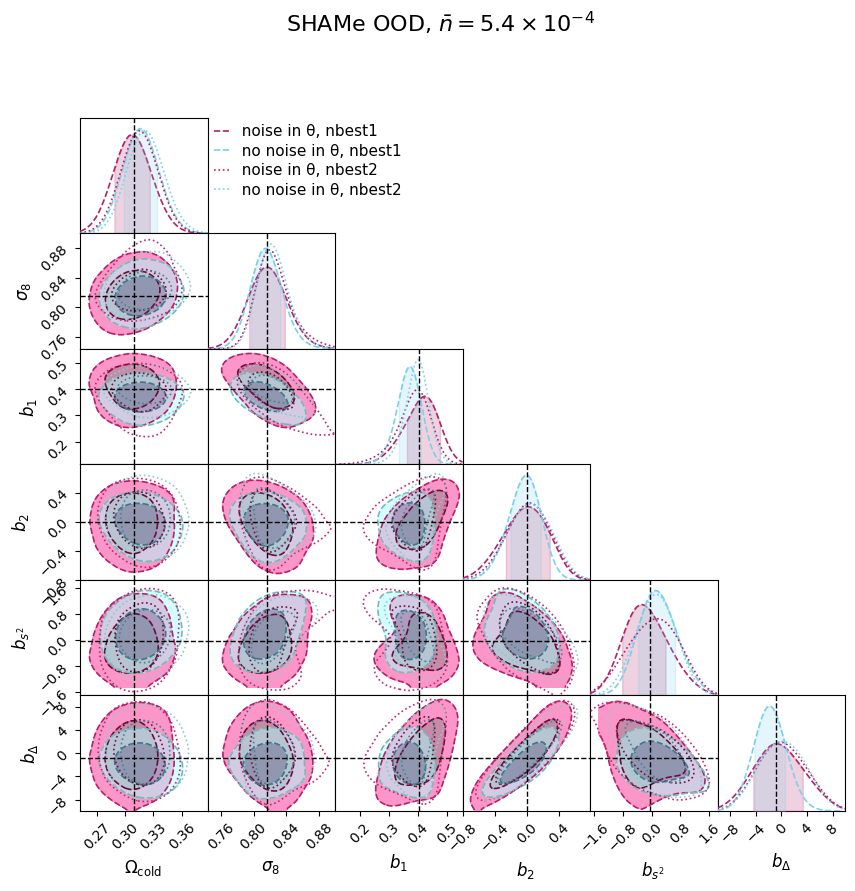

In [3]:
PARAM_NAMES_PLOT = ["omega_cold", "sigma8_cold", "b1", "b2", "bs2", "bl"]

for tag_mock in NBAR_TAGS:
    samples_list, labels, colors, linestyles, shades, tags = [], [], [], [], [], []
    for label, suffix, color, ls, shade in MODELS:
        s = load_shame_samples(suffix, tag_mock)
        if s is None:
            print(f"{tag_mock}: missing {label}")
            continue
        samples_list.append(s); labels.append(label); colors.append(color)
        linestyles.append(ls); shades.append(shade); tags.append(suffix)
    fig = plotter.plot_contours_inf(
        param_names=PARAM_NAMES_PLOT, idx_obs=0, theta_obs_true=None,
        inf_methods=["sbi"] * len(samples_list), tags_inf=tags, tags_test=[""] * len(tags),
        samples_list=samples_list, labels=labels, colors=colors,
        linestyles=linestyles, shades=shades, linewidths=[1.2] * len(tags),
        unreparameterize=True, add_truth=True,
        truth_locations=[shame_truth(tag_mock, PARAM_NAMES_PLOT)], truth_colors=["k"],
        figsize=(9, 9), fontsize_legend=11, title=f"SHAMe OOD, {NBAR_LABELS[tag_mock]}",
        legend_location=(0, 1), legend_loc="upper left", loc_legend=None, show=False,
    )
    if fig is not None:
        fig.savefig(FIG_DIR / f"contours_noise_ab_shame{tag_mock}.pdf", bbox_inches="tight")
    plt.show()

### Summary: posterior mean ± std and (mean − truth)/σ

Computed in the NPE coordinates (σ8×b1, σ8²×b2, …).

In [4]:
import pandas as pd

KEYS = ["omega_cold", "sigma8_cold", "sigma8_cold_x_b1", "sigma8_cold_sq_x_b2", "sigma8_cold_sq_x_bs2", "sigma8_cold_x_bl"]

def truth_rp(tag_mock):
    t = data_loader.load_params_ood("shame", tag_mock)
    s8 = t["sigma8_cold"]
    return dict(omega_cold=t["omega_cold"], sigma8_cold=s8, sigma8_cold_x_b1=s8 * t["b1"],
                sigma8_cold_sq_x_b2=s8**2 * t["b2"], sigma8_cold_sq_x_bs2=s8**2 * t["bs2"],
                sigma8_cold_x_bl=s8 * t["bl"])

rows = []
for tag_mock in NBAR_TAGS:
    tr = truth_rp(tag_mock)
    for label, suffix, *_ in MODELS:
        s = load_shame_samples(suffix, tag_mock)
        if s is None:
            continue
        arr, names = s
        row = {"nbar": tag_mock.replace("_nbar", ""), "model": label}
        for k in KEYS:
            x = arr[:, names.index(k)]
            row[k] = f"{x.mean():.3f}±{x.std():.3f} ({(x.mean() - tr[k]) / x.std():+.1f})"
        rows.append(row)
pd.set_option("display.max_colwidth", None)
pd.DataFrame(rows).set_index(["nbar", "model"])

omega_cold         sigma8_cold  \
nbar    model                                                           
0.00011 noise in θ, nbest1     0.322±0.015 (+0.8)  0.824±0.019 (+0.4)   
        no noise in θ, nbest1  0.326±0.015 (+1.1)  0.826±0.017 (+0.6)   
        noise in θ, nbest2     0.324±0.015 (+1.0)  0.824±0.019 (+0.4)   
        no noise in θ, nbest2  0.328±0.016 (+1.2)  0.829±0.018 (+0.8)   
0.00022 noise in θ, nbest1     0.313±0.015 (+0.3)  0.820±0.019 (+0.2)   
        no noise in θ, nbest1  0.319±0.015 (+0.7)  0.821±0.015 (+0.3)   
        noise in θ, nbest2     0.318±0.015 (+0.6)  0.825±0.018 (+0.5)   
        no noise in θ, nbest2  0.323±0.016 (+0.9)  0.827±0.017 (+0.7)   
0.00054 noise in θ, nbest1     0.308±0.017 (-0.1)  0.818±0.020 (+0.1)   
        no noise in θ, nbest1  0.317±0.016 (+0.5)  0.816±0.016 (+0.0)   
        noise in θ, nbest2     0.315±0.016 (+0.4)  0.825±0.019 (+0.5)   
        no noise in θ, nbest2  0.322±0.016 (+0.8)  0.824±0.016 (+0.5)   

                                 sigma8_cold_x_b1  sigma8_cold_sq_x_b2  \
nbar    model                                                            
0.00011 noise in θ, nbest1     0.410±0.031 (-0.7)   0.030±0.172 (-0.1)   
        no noise in θ, nbest1  0.405±0.027 (-1.0)  -0.057±0.151 (-0.7)   
        noise in θ, nbest2     0.409±0.032 (-0.7)   0.002±0.164 (-0.3)   
        no noise in θ, nbest2  0.404±0.030 (-0.9)  -0.046±0.173 (-0.5)   
0.00022 noise in θ, nbest1     0.376±0.034 (-0.3)   0.026±0.161 (+0.0)   
        no noise in θ, nbest1  0.357±0.023 (-1.3)  -0.045±0.124 (-0.5)   
        noise in θ, nbest2     0.369±0.031 (-0.6)   0.015±0.158 (-0.0)   
        no noise in θ, nbest2  0.365±0.026 (-0.8)  -0.037±0.166 (-0.3)   
0.00054 noise in θ, nbest1     0.333±0.038 (+0.1)  -0.018±0.165 (-0.1)   
        no noise in θ, nbest1  0.300±0.024 (-1.2)  -0.025±0.116 (-0.2)   
        noise in θ, nbest2     0.315±0.035 (-0.4)   0.009±0.156 (+0.1)   
        no noise in θ, nbest2  0.326±0.023 (-0.1)   0.023±0.159 (+0.2)   

                              sigma8_cold_sq_x_bs2     sigma8_cold_x_bl  
nbar    model                                                            
0.00011 noise in θ, nbest1     -0.085±0.378 (-0.0)  -0.555±2.864 (+0.1)  
        no noise in θ, nbest1   0.136±0.331 (+0.6)  -2.097±2.410 (-0.5)  
        noise in θ, nbest2     -0.013±0.432 (+0.1)  -0.948±2.727 (-0.0)  
        no noise in θ, nbest2   0.050±0.358 (+0.3)  -1.510±2.864 (-0.2)  
0.00022 noise in θ, nbest1     -0.138±0.346 (-0.2)  -0.162±2.676 (+0.2)  
        no noise in θ, nbest1   0.097±0.284 (+0.5)  -1.816±1.907 (-0.6)  
        noise in θ, nbest2     -0.046±0.430 (+0.0)  -0.165±2.654 (+0.2)  
        no noise in θ, nbest2   0.064±0.336 (+0.4)  -1.149±2.707 (-0.2)  
0.00054 noise in θ, nbest1     -0.083±0.379 (-0.1)  -0.321±2.886 (+0.1)  
        no noise in θ, nbest1   0.127±0.323 (+0.5)  -1.442±1.786 (-0.4)  
        noise in θ, nbest2      0.043±0.441 (+0.2)   0.108±2.758 (+0.3)  
        no noise in θ, nbest2   0.080±0.336 (+0.3)   0.133±2.652 (+0.3)

### Notes

- **All models recover the SHAMe cosmology within about 1.2σ at every $\bar n$.**
- **Noise in θ is a little less biased.** Ω_c sits about 0.4σ closer to truth, and σ8·b1 is noticeably closer at 2.2e-4 and 5.4e-4 for nbest1.
- **No noise in θ gives slightly tighter σ8 and σ8·b1**, by about 15%.
- **b2, bs2 and bl are prior-dominated** for both choices.

**Why the two should agree in principle.** The training data are the same in both runs, with noise drawn from the $A_n$ prior. Dropping $A_n$ from θ doesn't stop the noise from varying. The no-noise NPE is fit to the same joint $p(\theta_{\rm cosmo,bias}, A_n, x)$ and learns $p(\theta_{\rm cosmo,bias}\mid x)$ directly, which is that distribution already marginalized over $A_n$. The noise-in-θ NPE learns the joint posterior, and we marginalize afterwards by ignoring the $A_n$ columns. For a perfectly trained network the cosmology and bias marginals are identical.

**So the differences here are training effects, not a statistical cost.** The flow has to model an 11-D vs a 6-D density with the same hyperparameters and training budget. A tighter marginal from one model can't be read as more information. It is either a more accurate fit or overconfidence, and only calibration on held-out sims can tell which. Coverage (TARP/rank) on the v2 coverage set and the matched-phase test will settle the choice.

## 2. SHAMe vs phase-matched mock ($\bar n=2.2\times10^{-4}$)

The matched mock uses the SHAMe Rings initial conditions (seed −406168, pair mean over the 0/π phases), populated with our perturbative bias model at the SHAMe biases plus the best-fit noise (`_biasshame_noisebest_p0_n1`), with 10 noise realizations (`_noisematched`).

Both mocks share the same phases, so cosmic variance largely cancels in the difference. **SHAMe − matched** therefore isolates the shift caused by real galaxy formation versus our forward model. **Matched − truth** is that phase's cosmic variance plus network error.

"Matched (mean)" is the posterior on the mean statistic over the 10 noise realizations. The individual posteriors are also summarized in the table.

nbest0: no samples yet


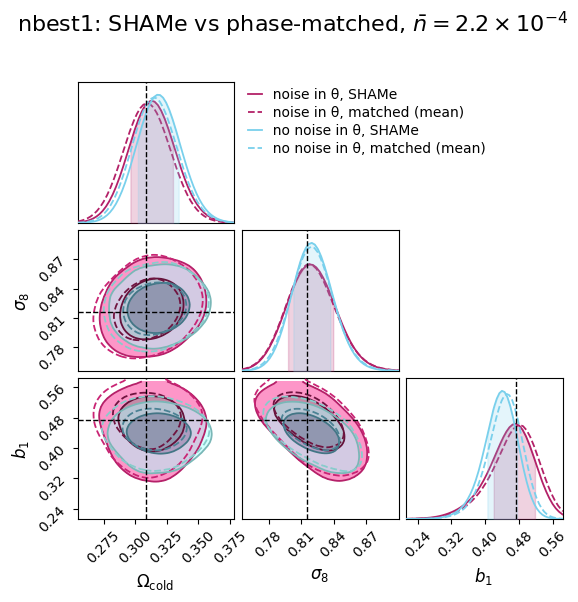

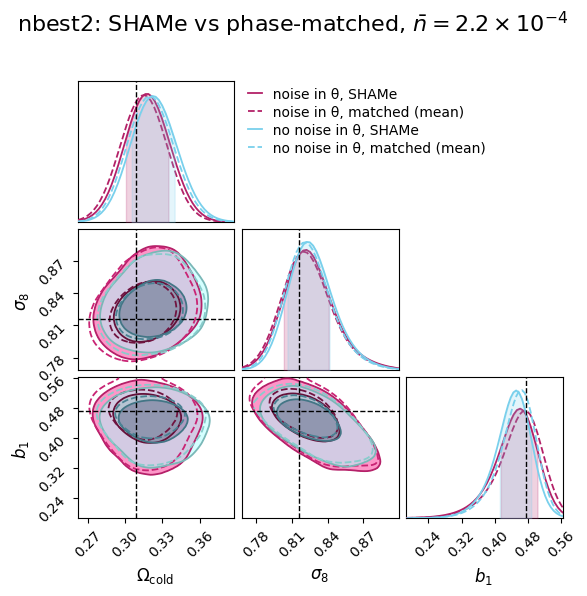

In [5]:
M_TAG = "samples_test_muchisimocks_pk_pgm_kp0.35_kpgm0.25_shamematched_p0_n10_biasshame_noisebest_p0_n1_noisematched"

def load_matched(suffix, mean=True):
    d = DIR_SBI / f"{TAG_MODEL}{suffix}"
    fn = d / f"{M_TAG}{'_mean' if mean else ''}_pred.npy"
    if not fn.exists():
        return None
    names = list(np.loadtxt(d / "param_names.txt", dtype=str))
    s = np.load(fn)
    if mean:
        return (s[:, 0, :] if s.ndim == 3 else s), names
    return s, names   # (n_samples, n_real, n_params)

tag_mock = "_nbar0.00022"
for nb_ in (0, 1, 2):
    samples_list, labels, colors, linestyles, shades, tags = [], [], [], [], [], []
    for noise, color in (("", COLOR_NOISE), ("_nonoise", COLOR_NONOISE)):
        suffix = f"{nb_}{noise}"
        lab = "noise in θ" if noise == "" else "no noise in θ"
        for kind, loader, ls, shade in (("SHAMe", lambda: load_shame_samples(suffix, tag_mock), "-", True),
                                        ("matched (mean)", lambda: load_matched(suffix), "--", False)):
            s = loader()
            if s is None:
                continue
            samples_list.append(s); labels.append(f"{lab}, {kind}"); colors.append(color)
            linestyles.append(ls); shades.append(shade); tags.append(suffix + kind)
    if not samples_list:
        print(f"nbest{nb_}: no samples yet")
        continue
    fig = plotter.plot_contours_inf(
        param_names=["omega_cold", "sigma8_cold", "b1"], idx_obs=0, theta_obs_true=None,
        inf_methods=["sbi"] * len(samples_list), tags_inf=tags, tags_test=[""] * len(tags),
        samples_list=samples_list, labels=labels, colors=colors,
        linestyles=linestyles, shades=shades, linewidths=[1.3] * len(tags),
        unreparameterize=True, add_truth=True,
        truth_locations=[shame_truth(tag_mock, ["omega_cold", "sigma8_cold", "b1"])], truth_colors=["k"],
        figsize=(6, 6), fontsize_legend=10, title=f"nbest{nb_}: SHAMe vs phase-matched, {NBAR_LABELS[tag_mock]}",
        legend_location=(0, 1), legend_loc="upper left", loc_legend=None, show=False,
    )
    if fig is not None:
        fig.savefig(FIG_DIR / f"contours_shame_vs_matched_nbest{nb_}.pdf", bbox_inches="tight")
    plt.show()

In [6]:
rows = []
tr = truth_rp(tag_mock)
for label, suffix, *_ in MODELS:
    sh, mm, ind = load_shame_samples(suffix, tag_mock), load_matched(suffix), load_matched(suffix, mean=False)
    if sh is None or mm is None or ind is None:
        continue
    names = sh[1]
    row = {"model": label}
    for k in ["omega_cold", "sigma8_cold", "sigma8_cold_x_b1"]:
        i = names.index(k)
        xs, xm = sh[0][:, i], mm[0][:, i]
        mu_ind = ind[0][:, :, i].mean(0)
        row[f"{k}: SHAMe"] = f"{(xs.mean() - tr[k]) / xs.std():+.2f}"
        row[f"{k}: matched"] = f"{(xm.mean() - tr[k]) / xm.std():+.2f}"
        row[f"{k}: SHAMe−matched"] = f"{(xs.mean() - xm.mean()) / xm.std():+.2f}"
        row[f"{k}: noise-real scatter"] = f"{mu_ind.std() / xm.std():.2f}"
    rows.append(row)
df = pd.DataFrame(rows).set_index("model")
df.columns = pd.MultiIndex.from_tuples([tuple(c.split(": ")) for c in df.columns])
print("all entries in units of the posterior σ")
df

all entries in units of the posterior σ


omega_cold                                           \
                           SHAMe matched SHAMe−matched noise-real scatter   
model                                                                       
noise in θ, nbest1         +0.30   +0.05         +0.25               0.10   
no noise in θ, nbest1      +0.67   +0.45         +0.21               0.09   
noise in θ, nbest2         +0.59   +0.39         +0.20               0.11   
no noise in θ, nbest2      +0.92   +0.75         +0.17               0.10   

                      sigma8_cold                                           \
                            SHAMe matched SHAMe−matched noise-real scatter   
model                                                                        
noise in θ, nbest1          +0.21   +0.18         +0.03               0.16   
no noise in θ, nbest1       +0.33   +0.29         +0.02               0.19   
noise in θ, nbest2          +0.50   +0.41         +0.09               0.13   
no noise in θ, nbest2       +0.65   +0.51         +0.14               0.18   

                      sigma8_cold_x_b1                        \
                                 SHAMe matched SHAMe−matched   
model                                                          
noise in θ, nbest1               -0.33   -0.10         -0.23   
no noise in θ, nbest1            -1.28   -0.89         -0.35   
noise in θ, nbest2               -0.59   -0.32         -0.26   
no noise in θ, nbest2            -0.83   -0.54         -0.27   

                                          
                      noise-real scatter  
model                                     
noise in θ, nbest1                  0.11  
no noise in θ, nbest1               0.15  
noise in θ, nbest2                  0.11  
no noise in θ, nbest2               0.13

### Notes (nbest1, nbest2)

- **SHAMe and the matched mock give almost the same posteriors.** SHAMe − matched is about +0.2σ in Ω_c, ≤0.1σ in σ8 and about −0.25σ in σ8·b1 for every model. At these scales, the remaining galaxy-formation mismatch is a small fraction of σ.
- **Most of the SHAMe offset from truth is already in the matched mock.** It comes from the shared phases (cosmic variance) and the network, not from SHAMe's galaxy formation.
- **The noise-in-θ and no-noise models disagree by about 0.5σ on the matched mock.**
  - On the matched mock the noise-in-θ models are close to truth (nbest1: +0.0σ Ω_c, +0.2σ σ8, −0.1σ σ8·b1). The no-noise models stay offset (Ω_c +0.4 to +0.7σ, σ8·b1 −0.5 to −0.9σ).
  - The matched mock comes from the model family both networks were trained on, so perfectly trained networks would give the same posterior. At least one network is therefore off by about 0.5σ.
  - The noise-in-θ model being closer to truth is suggestive. But truth − posterior for a single phase also contains that phase's unknown cosmic-variance shift, so the coverage tests have to settle which model is better calibrated.
- **The network-to-network spread is as large as the noise/no-noise difference.** With noise in θ, nbest1 and nbest2 differ by about 0.35σ in Ω_c on the matched mock (+0.05 vs +0.39). The 3-seed nbest0 runs (7986308) will show how much of this is seed noise as opposed to hyperparameters, which is what decides whether the noise/no-noise gap is significant.
- **The noise realization barely matters.** The scatter of posterior means across the 10 noise draws is about 0.1–0.2σ.